## **Apriori for Classification ( Class Association Rules, CBA )**

Associative classification mines the **frequent itemsets that contain the class** and keeps the rules `{attribute values} ⟶ class`. The classifier is the list of the best rules, where the **first matching rule decides**. This notebook keeps the original implementation and adds **a brute-force check of the Apriori search, the CBA database-coverage pruning, a cross-validation with the discretiser refitted in every fold, rule-level metrics, calibration and reference models**.

**Notebooks of this series:** 1. CN2 Rule Induction · 2. Expert Systems · 3. Case-Based Reasoning · 4. Apriori for Classification ( CBA ) · 5. Simple Rule Learners ( ZeroR, OneR, PRISM ) · 6. RIPPER · 7. Rules from Decision Trees · 8. RuleFit · 9. Fuzzy Rule-Based Classifier

### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Rule-Based Techniques**

Models whose knowledge is a set of **IF ⟶ THEN** rules: transparent, auditable and easy to explain.

| Technique | Where the rules come from | Idea |
|---|---|---|
| **CN2** | learned from data | ordered rule list built by beam search (entropy + significance test) |
| **Expert system** | written by specialists | inference engine + knowledge base, with certainty factors |
| **Case-Based Reasoning** | no explicit rules: past **cases** | retrieve · reuse · revise · retain |
| **Apriori (CBA)** | mined from data | class association rules: frequent itemsets → class |

This notebook focuses on **Apriori for Classification ( CBA )**. All the techniques of the series are applied to the same problem: **malignant × benign** tumours ( Breast Cancer dataset ).

### **2. Dataset and Preparation**

* Positive class = **malignant** (1) · 10 *mean* attributes (readable rules)
* Train/test split **70/30**, stratified
* For CN2 and Apriori the attributes are **discretised** in 3 quantile bins (*low / mid / high*), fitted on the **training set only**

In [4]:
#Load the Breast Cancer Dataset ( Positive Class = Malignant )
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer(as_frame=True)
cols = [c for c in data.data.columns if c.startswith("mean ")]            # 10 "mean" attributes
X = data.data[cols]
y = (data.target == 0).astype(int)                                        # 1 = malignant, 0 = benign
CLASS_NAMES = ["benign", "malignant"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape, "| malignant in train:", f"{y_train.mean():.1%}")
X_train.head(3)

train: (398, 10) | test: (171, 10) | malignant in train: 37.2%


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
78,20.18,23.97,143.70,1245.0,0.129,0.345,0.375,0.160,0.291,0.081
330,16.03,15.51,105.80,793.2,0.095,0.137,0.120,0.070,0.178,0.060
378,13.66,15.15,88.27,580.6,0.083,0.075,0.042,0.025,0.179,0.059


In [5]:
#Discretise the Attributes ( Quantile Bins Fitted on the Training Set )
from sklearn.preprocessing import KBinsDiscretizer

disc = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile", quantile_method="averaged_inverted_cdf").fit(X_train)
LEVELS = np.array(["low", "mid", "high"])

def to_categorical(Xnum):
    codes = disc.transform(Xnum).astype(int)
    return pd.DataFrame(LEVELS[codes], columns=[c.replace("mean ", "") for c in Xnum.columns], index=Xnum.index)

Xc_train, Xc_test = to_categorical(X_train), to_categorical(X_test)
Xc_train.head(3)

,radius,texture,perimeter,area,smoothness,compactness,concavity,concave points,symmetry,fractal dimension
78,high,high,high,high,high,high,high,high,high,high
330,high,low,high,high,mid,high,high,high,mid,mid
378,mid,low,mid,mid,low,mid,mid,mid,mid,mid


### **3. Apriori for Classification (Class Association Rules)**

**Associative classification (CBA):** mine **frequent itemsets** that include the class and keep the rules `{attribute values} ⟶ class`.

* **Support:** $P(A \cap C)$ · **Confidence:** $P(C \mid A)$ · **Lift:** $\dfrac{P(C \mid A)}{P(C)}$
* Classifier: rules sorted by **confidence**, then **support**, then **length**; the **first matching rule** decides (otherwise, the default class)

In [20]:
#Apriori Implementation ( Level-wise Search with Join and Prune )
from itertools import combinations

def apriori(B, min_support, max_len=3):
    """B: boolean DataFrame (transactions x items). Returns {itemset (tuple of column names): support}."""
    M_, n, names = B.to_numpy(), len(B), list(B.columns)
    freq = {}
    level = [(i,) for i in range(len(names)) if M_[:, i].mean() >= min_support]
    for c in level:
        freq[c] = M_[:, c[0]].mean()
    k = 1
    while level and k < max_len:
        prev = set(level)
        cands = {a[:-1] + (a[-1], b[-1]) for a in level for b in level if a[:-1] == b[:-1] and a[-1] < b[-1]}          # join
        cands = [c for c in cands if all(sub in prev for sub in combinations(c, k))]                                   # prune
        level = []
        for c in sorted(cands):
            s = M_[:, list(c)].all(axis=1).mean()
            if s >= min_support:
                freq[c] = s; level.append(c)
        k += 1
    return {tuple(names[i] for i in c): s for c, s in freq.items()}

#One-hot "transactions": attribute=value items + the class item
def to_transactions(Xcat, y=None):
    B = pd.get_dummies(Xcat.astype(str).apply(lambda col: col.name + "=" + col)).astype(bool)
    B.columns = [c.split("_", 1)[1] if "_" in c and "=" in c.split("_", 1)[1] else c for c in B.columns]
    if y is not None:
        B["class=" + CLASS_NAMES[0]] = (np.asarray(y) == 0); B["class=" + CLASS_NAMES[1]] = (np.asarray(y) == 1)
    return B

B_train = to_transactions(Xc_train, y_train)
freq = apriori(B_train, min_support=0.05, max_len=3)
print("transactions:", B_train.shape, "| frequent itemsets (support ≥ 5%, size ≤ 3):", len(freq))

transactions: (398, 32) | frequent itemsets (support ≥ 5%, size ≤ 3): 1631


In [21]:
#Generate the Class Association Rules ( Antecedent ⟶ Class )
def class_rules(freq, B, min_conf=0.6):
    class_items = [c for c in B.columns if c.startswith("class=")]
    rows = []
    for itemset, sup in freq.items():
        cls = [i for i in itemset if i.startswith("class=")]
        ante = tuple(i for i in itemset if not i.startswith("class="))
        if len(cls) != 1 or not ante:
            continue
        conf = sup / freq[ante]
        if conf >= min_conf:
            rows.append({"antecedent": ante, "class": cls[0].split("=")[1], "support": sup, "confidence": conf,
                         "lift": conf / freq[(cls[0],)], "length": len(ante)})
    df = pd.DataFrame(rows).sort_values(["confidence", "support", "length"], ascending=[False, False, True]).reset_index(drop=True)
    return df

rules_cba = class_rules(freq, B_train, min_conf=0.6)
print("class association rules (confidence ≥ 60%):", len(rules_cba))
rules_cba.head(8).assign(antecedent=lambda d: d["antecedent"].apply(lambda t: " AND ".join(t)))

class association rules (confidence ≥ 60%): 317


,antecedent,class,support,confidence,lift,length
0,perimeter=low AND concave points=low,benign,0.214,1.0,1.592,2
1,radius=low AND concave points=low,benign,0.209,1.0,1.592,2
2,area=low AND concave points=low,benign,0.209,1.0,1.592,2
3,texture=high AND concave points=high,malignant,0.166,1.0,2.689,2
4,concave points=low AND symmetry=low,benign,0.156,1.0,1.592,2
5,texture=low AND concavity=low,benign,0.146,1.0,1.592,2
6,texture=low AND perimeter=low,benign,0.143,1.0,1.592,2
7,texture=low AND compactness=low,benign,0.141,1.0,1.592,2


In [ ]:
#Dictionary Used to Collect the Test Metrics of This Notebook ( the Cells Below Add Their Results to It )
results = {}

rules used (confidence ≥ 80%): 257


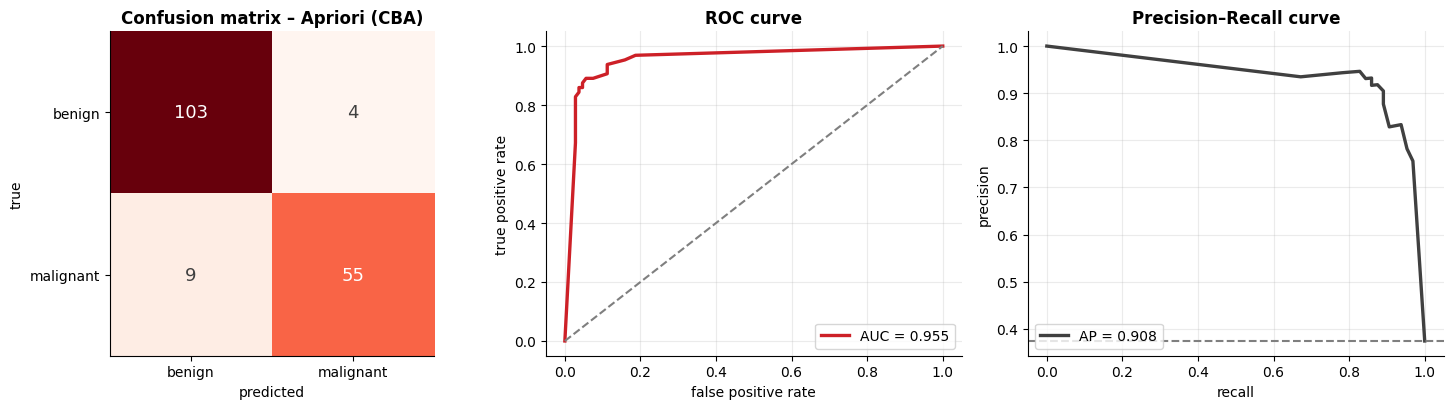

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
Apriori (CBA),0.924,0.911,0.932,0.859,0.894,0.837,0.955,0.908


In [22]:
#CBA Classifier: First Matching Rule Decides
def cba_predict_proba(rules, Xcat, default_p):
    B = to_transactions(Xcat).reindex(columns=B_train.columns.drop([c for c in B_train.columns if c.startswith("class=")]), fill_value=False)
    p, free = np.full(len(Xcat), default_p, dtype=float), np.ones(len(Xcat), bool)
    for r in rules.itertuples():
        m = B[list(r.antecedent)].all(axis=1).to_numpy() & free
        p[m] = r.confidence if r._2 == CLASS_NAMES[1] else 1 - r.confidence
        free &= ~m
    return p

prior_malignant = y_train.mean()
rules_cba = class_rules(freq, B_train, min_conf=0.8)                      # higher confidence for the classifier
proba_cba = cba_predict_proba(rules_cba, Xc_test, prior_malignant)
pred_cba = (proba_cba > 0.5).astype(int)
print("rules used (confidence ≥ 80%):", len(rules_cba))
results["Apriori (CBA)"] = report_binary(y_test, pred_cba, proba_cba, "Apriori (CBA)", CLASS_NAMES)
results["Apriori (CBA)"].to_frame().T

#### **Apriori-Specific Metrics**

The **quality of each rule** (support, confidence, lift) and how the **thresholds** change the number of rules and the accuracy.

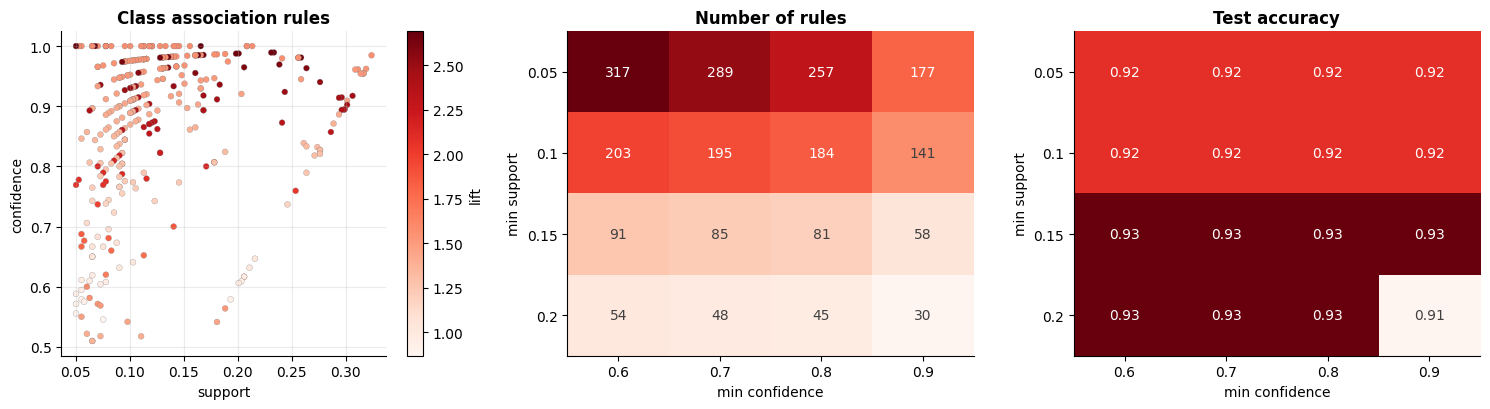

In [23]:
#Rule Quality ( Support x Confidence, Colored by Lift ) and Threshold Sensitivity
all_rules = class_rules(freq, B_train, min_conf=0.5)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sc = axes[0].scatter(all_rules["support"], all_rules["confidence"], c=all_rules["lift"], cmap="Reds", s=18, edgecolor=GRAY, lw=0.2)
axes[0].set_xlabel("support"); axes[0].set_ylabel("confidence"); axes[0].set_title("Class association rules"); fig.colorbar(sc, ax=axes[0], label="lift")

sup_grid, conf_grid = [0.05, 0.1, 0.15, 0.2], [0.6, 0.7, 0.8, 0.9]
n_rules, acc = np.zeros((4, 4), int), np.zeros((4, 4))
for i, s in enumerate(sup_grid):
    for j, c in enumerate(conf_grid):
        r = all_rules[(all_rules["support"] >= s) & (all_rules["confidence"] >= c)]
        n_rules[i, j] = len(r)
        acc[i, j] = accuracy_score(y_test, (cba_predict_proba(r, Xc_test, prior_malignant) > 0.5).astype(int)) if len(r) else np.nan
for ax, mat, title, fmt in [(axes[1], n_rules, "Number of rules", "{:.0f}"), (axes[2], acc, "Test accuracy", "{:.2f}")]:
    ax.imshow(mat, cmap="Reds", aspect="auto"); ax.grid(False)
    ax.set_xticks(range(4)); ax.set_xticklabels(conf_grid); ax.set_yticks(range(4)); ax.set_yticklabels(sup_grid)
    ax.set_xlabel("min confidence"); ax.set_ylabel("min support"); ax.set_title(title)
    annotate_heatmap(ax, mat, fmt)
plt.tight_layout(); plt.show()

### **4. Quality Metrics Beyond the Original Ones**

In [ ]:
#Quality Check 1: the Apriori Search vs a Brute-Force Count of Every Itemset with up to 3 Items ( Ground Truth )
from itertools import combinations
M_train = B_train.to_numpy()
min_sup = 0.05
truth = {}
for size in (1, 2, 3):
    for cols_ in combinations(range(M_train.shape[1]), size):
        s = M_train[:, list(cols_)].all(axis=1).mean()
        if s >= min_sup:
            truth[tuple(B_train.columns[c] for c in cols_)] = s
found = {tuple(k): v for k, v in freq.items()}
both = set(found) & set(truth)
print(f"itemsets found by apriori(): {len(found)} | brute-force ground truth: {len(truth)} | precision: {len(both) / len(found):.3f} | recall: {len(both) / len(truth):.3f} | max support error: {max(abs(found[k] - truth[k]) for k in both):.1e}")

In [ ]:
#Quality Check 2: How Many Test Cases Are Decided by a Rule, and How Good Is Each Decision?
B_test = to_transactions(Xc_test).reindex(columns=B_train.columns.drop([c for c in B_train.columns if c.startswith("class=")]), fill_value=False)
free = np.ones(len(Xc_test), bool)
decided_by, correct_rule = np.full(len(Xc_test), -1), np.zeros(len(Xc_test), bool)
for pos, r in enumerate(rules_cba.itertuples()):
    m = B_test[list(r.antecedent)].all(axis=1).to_numpy() & free
    decided_by[m] = pos
    correct_rule[m] = (y_test.to_numpy()[m] == (1 if r._2 == CLASS_NAMES[1] else 0))
    free &= ~m
by_rule = decided_by >= 0
print(f"test cases decided by a rule: {by_rule.mean():.1%} ( accuracy of those decisions: {correct_rule[by_rule].mean():.3f} ) | cases left to the default class: {(~by_rule).mean():.1%}")
print(f"rules that decided at least one test case: {len(np.unique(decided_by[by_rule]))} of {len(rules_cba)}")

### **5. Reducing the Rule Set: Database Coverage ( CBA-CB )**

The classifier of the original cell uses **every** rule above the confidence threshold. **CBA-CB** keeps a rule only if it **correctly classifies at least one training case that is still uncovered**, removes the cases it covers, and cuts the list where the **training errors** are minimal.

In [ ]:
#Database-Coverage Pruning of the Rule List ( CBA-CB ) and Comparison with the Full Rule List
def coverage_prune(rules, B, y):
    y = np.asarray(y)
    remaining, kept, errors_rules, trace = np.ones(len(B), bool), [], 0, []
    Bn = B[[c for c in B.columns if not c.startswith("class=")]]
    for r in rules.itertuples():
        m = Bn[list(r.antecedent)].all(axis=1).to_numpy() & remaining
        cls = 1 if r._2 == CLASS_NAMES[1] else 0
        if not (m & (y == cls)).any():
            continue
        kept.append(r.Index); remaining &= ~m
        errors_rules += int((m & (y != cls)).sum())
        rest = y[remaining]
        default_err = int(min((rest == 0).sum(), (rest == 1).sum())) if len(rest) else 0
        trace.append(errors_rules + default_err)
        if not remaining.any():
            break
    cut = int(np.argmin(trace)) + 1
    return rules.loc[kept[:cut]], trace

pruned, trace = coverage_prune(rules_cba, B_train, y_train)
proba_pruned = cba_predict_proba(pruned, Xc_test, prior_malignant)
pred_pruned = (proba_pruned > 0.5).astype(int)
results["Apriori (CBA, database coverage)"] = report_binary(y_test, pred_pruned, proba_pruned, "CBA with database coverage", CLASS_NAMES, plot=False)
print(f"rules: {len(rules_cba)} -> {len(pruned)} after database coverage ( {len(pruned) / len(rules_cba):.1%} of the rules )")
pd.DataFrame(results).T[["accuracy", "precision", "recall", "F1", "ROC AUC", "PR AUC"]].round(3)

In [ ]:
#Repeated Stratified CV on the Training Set: Discretiser, Apriori and Rules Refitted Inside Every Fold ( Full List vs Database Coverage )
from sklearn.model_selection import RepeatedStratifiedKFold
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

def cv_cba(prune):
    accs, aucs, sizes = [], [], []
    for tr, te in cv_rep.split(X_train, y_train):
        d = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile", quantile_method="averaged_inverted_cdf").fit(X_train.iloc[tr])
        codes = lambda part: pd.DataFrame(LEVELS[d.transform(part).astype(int)], columns=Xc_train.columns, index=part.index)
        Xa, Xb, ya, yb = codes(X_train.iloc[tr]), codes(X_train.iloc[te]), y_train.iloc[tr], y_train.iloc[te]
        Ba = to_transactions(Xa, ya)
        rules_f = class_rules(apriori(Ba, min_support=0.05, max_len=3), Ba, min_conf=0.8)
        if prune:
            rules_f, _ = coverage_prune(rules_f, Ba, ya)
        cols_ = Ba.columns.drop([c for c in Ba.columns if c.startswith("class=")])
        Bb = to_transactions(Xb).reindex(columns=cols_, fill_value=False)
        p, free = np.full(len(Xb), ya.mean()), np.ones(len(Xb), bool)
        for r in rules_f.itertuples():
            m = Bb[list(r.antecedent)].all(axis=1).to_numpy() & free
            p[m] = r.confidence if r._2 == CLASS_NAMES[1] else 1 - r.confidence
            free &= ~m
        accs.append(((p > 0.5).astype(int) == yb.to_numpy()).mean()); aucs.append(roc_auc_score(yb, p)); sizes.append(len(rules_f))
    return np.array(accs), np.array(aucs), np.array(sizes)

cv_stats = {}
for label, prune in [("Apriori (CBA, all rules)", False), ("Apriori (CBA, database coverage)", True)]:
    a, u, s = cv_cba(prune)
    cv_stats[label] = {"accuracy ( mean )": a.mean(), "accuracy ( std )": a.std(), "ROC AUC ( mean )": u.mean(), "ROC AUC ( std )": u.std(), "rules ( mean )": s.mean()}
pd.DataFrame(cv_stats).T.round(3)

In [ ]:
#Uncertainty of the Test Metrics ( Bootstrap of the Test Cases, 1,000 Resamples )
def bootstrap_ci(y_true, pred, score, n_boot=1000, seed=RANDOM_STATE):
    rng_b = np.random.default_rng(seed)
    y_true, pred, score = np.asarray(y_true), np.asarray(pred), np.asarray(score)
    acc, auc = [], []
    for _ in range(n_boot):
        i = rng_b.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[i])) < 2:
            continue
        acc.append((pred[i] == y_true[i]).mean())
        auc.append(roc_auc_score(y_true[i], score[i]))
    return pd.DataFrame({"accuracy": np.percentile(acc, [2.5, 50, 97.5]), "ROC AUC": np.percentile(auc, [2.5, 50, 97.5])}, index=["2.5%", "median", "97.5%"]).T

print("the test set has", len(y_test), "cases: differences smaller than these intervals are not reliable")
bootstrap_ci(y_test, pred_cba, proba_cba).round(3)

In [ ]:
#Calibration of the Predicted Probabilities ( Brier Score and Reliability Curve )
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

proba_cba_ARRAY = np.asarray(proba_cba, dtype=float)
frac_pos, mean_pred = calibration_curve(y_test, proba_cba_ARRAY, n_bins=5, strategy="quantile")                       # bins with the same number of cases
print(f"Brier score: {brier_score_loss(y_test, proba_cba_ARRAY):.4f} | Brier score of a model that always predicts the training prevalence: {brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.4f} ( lower is better )")
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", label="perfect calibration"); ax.plot(mean_pred, frac_pos, color=RED, marker="o", label="Apriori (CBA)")
ax.set_xlabel("mean predicted probability ( 5 bins of equal size )"); ax.set_ylabel("observed share of malignant"); ax.set_title("Reliability curve"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
#Reference Models on the Same Split ( Is the Technique Better than a Trivial or a Standard Model? )
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

references = {"Majority class": DummyClassifier(strategy="prior"),
              "Decision tree ( depth 3 )": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
              "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))}
reference_rows = {}
for ref_name, model in references.items():
    model.fit(X_train, y_train)
    reference_rows[ref_name] = report_binary(y_test, model.predict(X_test), model.predict_proba(X_test)[:, 1], ref_name, CLASS_NAMES, plot=False)
metric_cols = ["accuracy", "precision", "recall", "F1", "ROC AUC", "PR AUC"]
pd.concat([pd.DataFrame(results).T[metric_cols], pd.DataFrame(reference_rows).T[metric_cols]]).round(3)

### **6. Takeaways**

* The **Apriori search was verified** against a brute-force count: it returns exactly the frequent itemsets and their supports
* **Most of the 257 rules never decide anything**: the first matching rule wins, so only a few rules are used; **database coverage** keeps a compact list for a similar accuracy ( compare the two lines of the cross-validation table )
* The **discretiser was refitted inside each fold** in the cross-validation; fitting it once on all the training cases would let the validation cases choose the cut points
* The probabilities of the rules ( their confidences ) were measured on the same training cases that selected the rules, so they can be optimistic: check the Brier score and the reliability curve before using them as probabilities
* For a version with the numeric attributes discretised by CBA's own procedure on the Wine data, see notebook *9 of the association-techniques series*